# BÀI TẬP THỰC HÀNH 2


## Sử dụng thư viện nào hãy import ở trên đây

In [68]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.arima.model import ARIMA

from statsmodels.graphics import tsaplots
from datetime import datetime, timedelta

## BÀI 1: KHÁM PHÁ DỮ LIỆU (EDA)
**Dataset sử dụng:** Dataset 1 - Monthly Retail Sales (`a10.csv`)
- Mô tả: Doanh số bán lẻ dược phẩm theo tháng (Australia / US Monthly Sales), từ 07/1991 đến 06/2008..
- Nguồn dữ liệu: https://raw.githubusercontent.com/selva86/datasedf/master/a10.csv

### 1. Tải và đọc dữ liệu

In [36]:
url = "https://raw.githubusercontent.com/selva86/datasets/master/a10.csv"
df = pd.read_csv(url)

# Xem vài dòng đầu
print("Kích thước dữ liệu:", df.shape)
print("\nTên cột:", df.columns.tolist())
display(df.head())
display(df.tail())

Kích thước dữ liệu: (204, 2)

Tên cột: ['date', 'value']


,date,value
0,1991-07-01,3.526591
1,1991-08-01,3.180891
2,1991-09-01,3.252221
3,1991-10-01,3.611003
4,1991-11-01,3.565869


,date,value
199,2008-02-01,21.654285
200,2008-03-01,18.264945
201,2008-04-01,23.107677
202,2008-05-01,22.912510
203,2008-06-01,19.431740


### 2. Chuyển cột date thành chỉ số thời gian
Chuyển `date` sang kiểu ngày tháng, sau đó đặt làm index

In [37]:
df["date"] = pd.to_datetime(df["date"])
df = df.set_index("date")

display(df.head())
print("Kiểu index:", type(df.index).__name__)
print("Khoảng thời gian:", df.index.min(), "đến", df.index.max())
print("Số quan sát hợp lệ:", len(df))
print("Tần suất thời gian ước tính: hàng tháng")

,value
date,
1991-07-01,3.526591
1991-08-01,3.180891
1991-09-01,3.252221
1991-10-01,3.611003
1991-11-01,3.565869


Kiểu index: DatetimeIndex
Khoảng thời gian: 1991-07-01 00:00:00 đến 2008-06-01 00:00:00
Số quan sát hợp lệ: 204
Tần suất thời gian ước tính: hàng tháng


### Mô tả dataset

In [38]:
df.describe()

,value
count,204.000000
mean,10.694430
std,5.956998
min,2.814520
25%,5.844095
50%,9.319345
75%,14.289964
max,29.665356


### 3. Vẽ đồ thị chuỗi thời gian

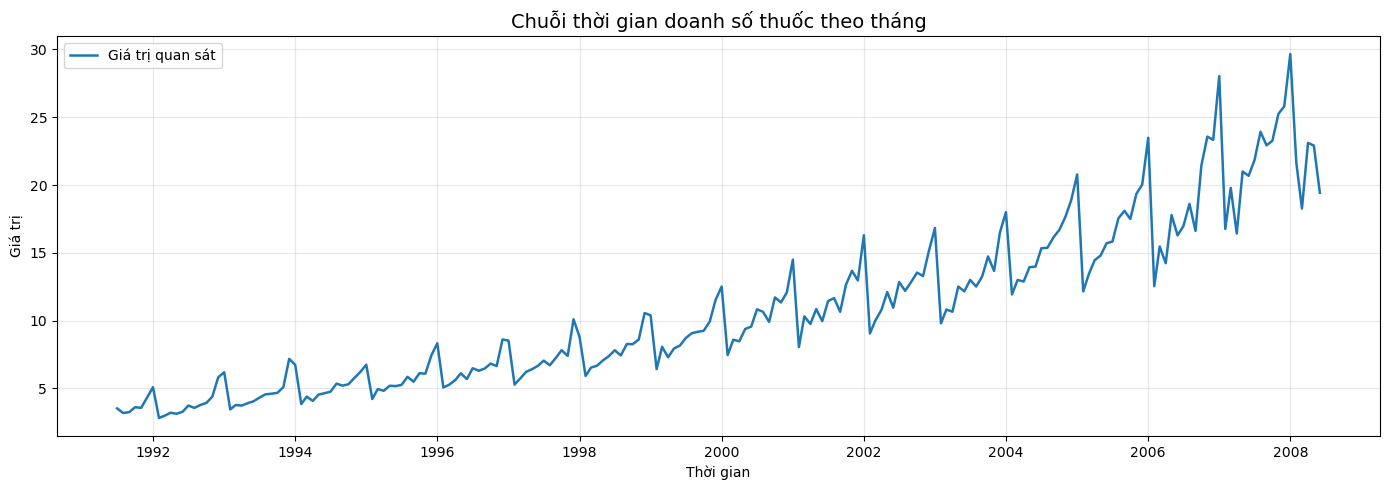

In [39]:
fig, ax = plt.subplots(figsize=(14, 5))


ax.plot(df.index, df["value"], linewidth=1.8, label="Giá trị quan sát")
ax.set_title("Chuỗi thời gian doanh số thuốc theo tháng", fontsize=14)
ax.set_xlabel("Thời gian")
ax.set_ylabel("Giá trị")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


### Trả lời câu hỏi số 1

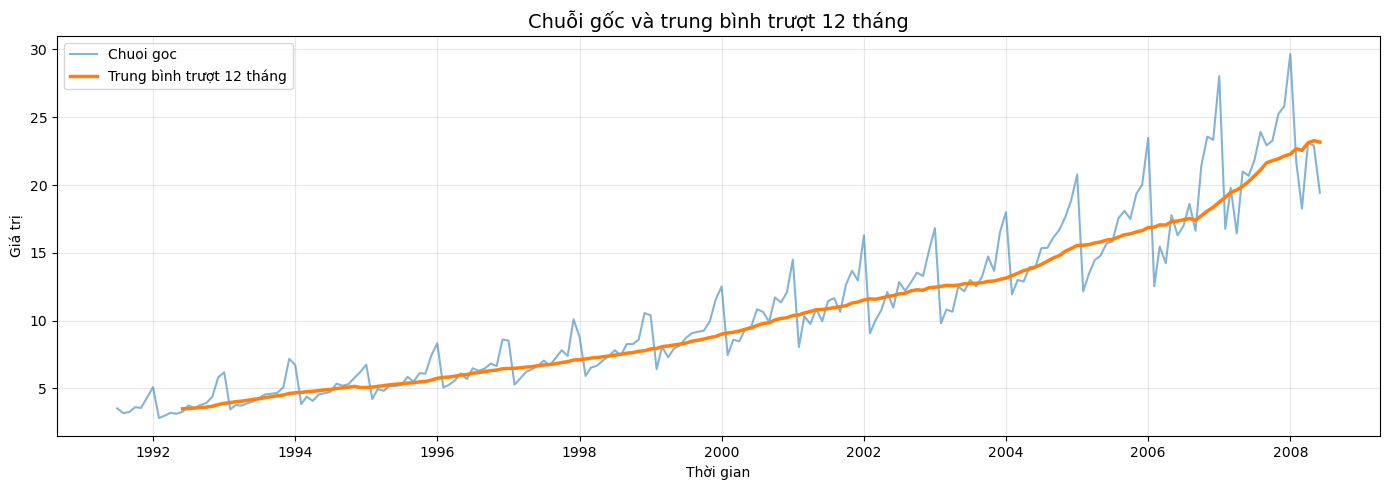

In [40]:
# Tính trung bình trượt 12 tháng với window=12 là 12 quan sát
rolling_12 = df["value"].rolling(window=12, min_periods=12).mean()

# Vẽ biểu đồ
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df.index, df["value"], alpha=0.55, label="Chuoi goc")
ax.plot(rolling_12.index, rolling_12, linewidth=2.5, label="Trung bình trượt 12 tháng")
ax.set_title("Chuỗi gốc và trung bình trượt 12 tháng", fontsize=14)
ax.set_xlabel("Thời gian")
ax.set_ylabel("Giá trị")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Trả lời câu hỏi số 2

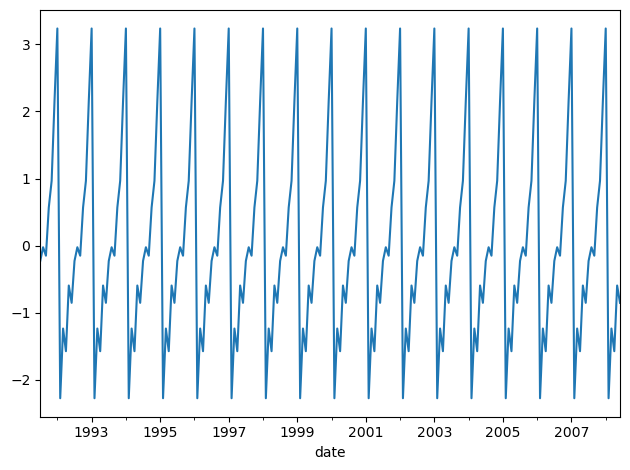

In [41]:
decomposition = seasonal_decompose(df["value"], model="additive", period=12)
fig = decomposition.seasonal.plot()
plt.tight_layout()
plt.show()

### Trả lời câu hỏi số 3

Kiểm tra kỳ vọng (mean)

In [42]:
month_mean = df.groupby(df.index.month)["value"].mean()
month_mean


date
1     14.171518
2      8.612831
3      9.489650
4      9.553137
5     10.563693
6     10.222276
7      9.986016
8     10.264747
9     10.234068
10    11.017340
11    11.486242
12    12.731636
Name: value, dtype: float64

Nhận xét kỳ vọng: 

Trung bình mỗi tháng qua nhiều năm cho thấy có sự thay đổi lớn
+ Tháng 1 qua tháng 2 doanh số giảm sút
+ Bắt đầu tới tháng 10 trở đi lại có thêm một đà tăng trưởng

-> Có sự thay đổi theo thời gian 

Kiểm tra phương sai

In [43]:
def error_value(xi, x_mean):
    # xi: a part value in a dataset
    # x: giá trị trung bình
    return xi - x_mean

In [44]:
month_var = df.groupby(df.index.month)["value"].var()
month_var

date
1     59.856821
2     26.054918
3     25.904618
4     28.668012
5     35.716560
6     29.288154
7     28.879170
8     34.727056
9     32.067604
10    37.281719
11    44.667671
12    40.342140
Name: value, dtype: float64

In [45]:
january_data = df[df.index.month == 1]
i = 0
jan_mean = month_mean.loc[1]
print("Sự chênh lệch giữa giá trị doanh số tháng 1 và trung bình tháng 1")
for date_val, temp_val in january_data['value'].items():
    year = date_val.year
    error = error_value(temp_val, jan_mean)
    print(f"Tháng 1 - {year}: {error}")

Sự chênh lệch giữa giá trị doanh số tháng 1 và trung bình tháng 1
Tháng 1 - 1992: -9.08318251117647
Tháng 1 - 1993: -7.9794498211764715
Tháng 1 - 1994: -7.440044431176472
Tháng 1 - 1995: -7.4220336911764715
Tháng 1 - 1996: -5.842065391176472
Tháng 1 - 1997: -5.647046501176472
Tháng 1 - 1998: -5.373004481176471
Tháng 1 - 1999: -3.7801019111764713
Tháng 1 - 2000: -1.6600551611764711
Tháng 1 - 2001: 0.3260635788235291
Tháng 1 - 2002: 2.1287517588235296
Tháng 1 - 2003: 2.6568321688235272
Tháng 1 - 2004: 3.832250438823529
Tháng 1 - 2005: 6.607205488823528
Tháng 1 - 2006: 9.315176488823528
Tháng 1 - 2007: 13.866865488823528
Tháng 1 - 2008: 15.493838488823528


Kết luận phương sai: Phương sai luôn thay đổi

Tìm cấu trúc tự tương quan

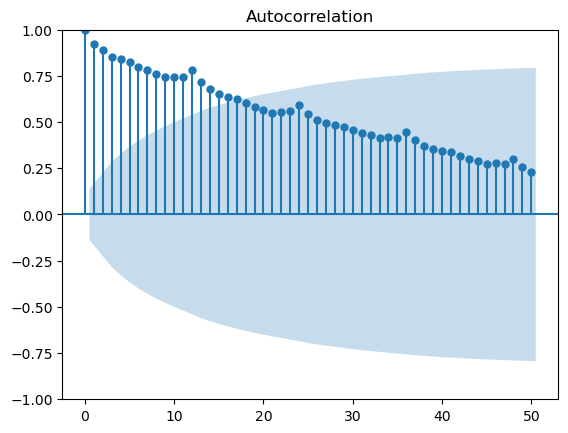

In [46]:
fig = tsaplots.plot_acf(df, lags=50) # 4 năm

Kết luận: Chuỗi thời gian này không có tính dừng

## BÀI 2: KIỂM ĐỊNH ADF TRÊN CHUỖI GỐC

In [47]:
result = adfuller(df['value'], autolag='AIC')

adf_stat, p_value, used_lag, nobs, crit_values = result[0], result[1], result[2], result[3], result[4]

print(f'ADF statistic : {adf_stat:.4f}')
print(f'p-value       : {p_value:.4f}')
print(f'Số độ trễ     : {used_lag}')
print(f'Số quan sát   : {nobs}')
print('Giá trị tới hạn:')
for level, value in crit_values.items():
    print(f'   {level}: {value:.4f}')

# Kết luận tự động
if p_value < 0.05:
    print('\nKết luận: Bác bỏ H0 -> Chuỗi DỪNG')
else:
    print('\nKết luận: Không bác bỏ H0 -> Chuỗi KHÔNG DỪNG')

ADF statistic : 3.1452
p-value       : 1.0000
Số độ trễ     : 15
Số quan sát   : 188
Giá trị tới hạn:
   1%: -3.4656
   5%: -2.8770
   10%: -2.5750

Kết luận: Không bác bỏ H0 -> Chuỗi KHÔNG DỪNG


### Trả lời câu hỏi số 1

Câu 1. H₀ của ADF là gì?

- **H₀:** Chuỗi có nghiệm đơn vị (unit root), tức là **chuỗi không dừng**.
- **H₁:** Chuỗi **dừng**.

ADF giả định ngay từ đầu là chuỗi *không dừng*. Muốn kết luận chuỗi dừng thì phải có đủ bằng chứng để bác bỏ H₀.

### Trả lời câu hỏi số 2

Câu 2. p-value cho biết điều gì?

p-value là xác suất thu được để đánh giá mức độ tin cậy của kết quả phân tích và xem liệu có đủ bằng chứng thống kê để bác bỏ giả thuyết H₀

- p < 0,05 → bác bỏ H₀ → chuỗi **dừng**
- p ≥ 0,05 → không bác bỏ H₀ → chuỗi **không dừng**

### Trả lời câu hỏi số 3

Câu 3. Chuỗi có dừng không?

Ở đây p = 1,0, lớn hơn rất nhiều so với 0,05, nên có thể thấy rằng đây là chuỗi không dừng.

## Bài 3: Sai phân & kiểm định lại

In [48]:
series = df["value"].asfreq("MS")      # MS = đầu mỗi tháng, khai báo dữ liệu theo tháng

In [49]:
def adf_report(x, name):
    stat, p, lags, nobs, crit, _ = adfuller(x, regression="c", autolag="AIC")
    kq = "DỪNG" if p <= 0.05 else "KHÔNG DỪNG"
    print(f"{name}: ADF = {stat:8.4f} | p-value = {p:.4f} | {kq}")
    return p

Sai phân lần 1

In [50]:
d1 = series.diff().dropna()                # sai phân bậc 1
r1 = adf_report(d1, "Sai phân bậc 1")

Sai phân bậc 1: ADF =  -2.4952 | p-value = 0.1167 | KHÔNG DỪNG


Sai phân lần 2

In [51]:
d2 = series.diff().diff().dropna()
r2 = adf_report(d2, "Sai phân bậc 2")

Sai phân bậc 2: ADF = -10.2923 | p-value = 0.0000 | DỪNG


Cách nhìn đồ thị để nói "dừng hay chưa":
   - Đường trung bình trượt (đỏ) có nằm ngang quanh một mức không?  Nằm ngang -> kỳ vọng ổn định.
   - Độ dao động có đều không (phình ra hay thu lại)?  Đều -> phương sai ổn định.

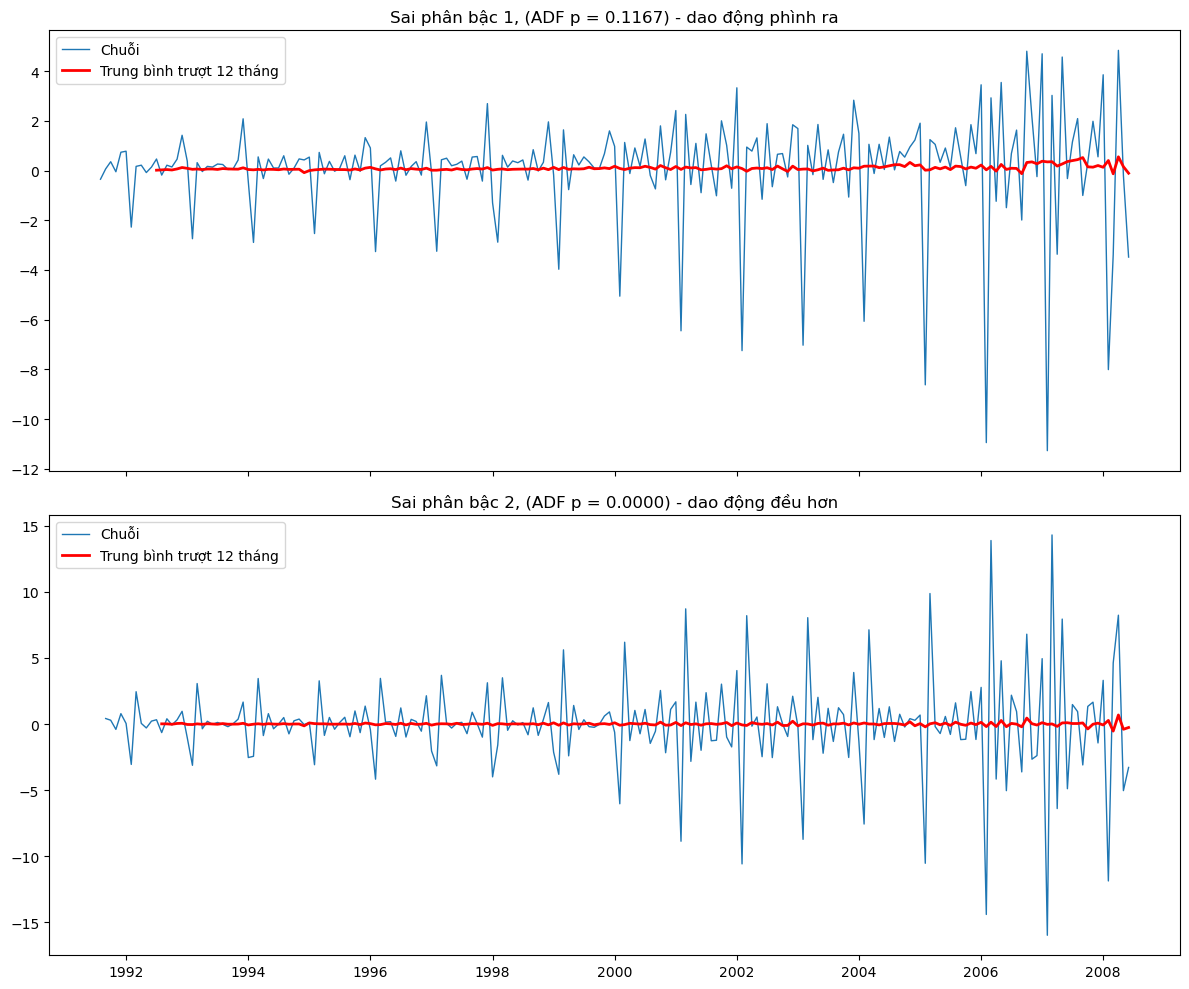

In [52]:
fig, axes = plt.subplots(2, 1, figsize=(12, 10), sharex=True)
for ax, x, title in [
    (axes[0], d1, f"Sai phân bậc 1, (ADF p = {r1:.4f}) - dao động phình ra"),
    (axes[1], d2, f"Sai phân bậc 2, (ADF p = {r2:.4f}) - dao động đều hơn"),
]:
    x = x.dropna()
    ax.plot(x, label="Chuỗi", lw=1)
    ax.plot(x.rolling(12).mean( ), color="red", lw=2, label="Trung bình trượt 12 tháng")
    
    ax.set_title(title)
    ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

## Bài 4: Phân tích ACF / PACF

d2 là biến cho chuỗi đã dừng => d=2 trong (p, d, q) vì d2 là sai phân bậc 2

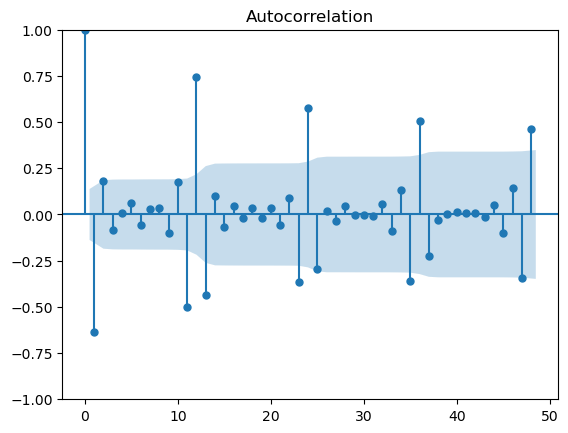

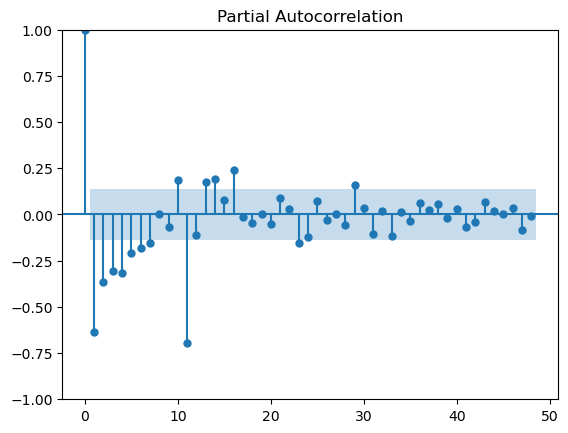

In [53]:
plot_acf(d2, lags=48)
plot_pacf(d2, lags= 48)
plt.show()

### Quy tắc để chọn p và q
+ Chọn p ta cần quan sát PACF
Dựa vào biểu đồ PACF đang dần đi về 0 tại vị trí lag = 2
+ Chọn q ta cần quan sát ACF
Dựa vào biểu đồ ACF đang dần đi về 0 tại vị trí lag = 2

In [54]:
p, d, q = 2, 2, 2

In [55]:
train_end = datetime(2004, 12, 1) #2004-12-01
test_end = datetime(2008, 6, 1) #2008-06-01

train_data = df[:train_end]
test_data = df[train_end + timedelta(days=1) : test_end]

In [56]:
model = ARIMA(train_data, order=(p, d, q))

c:\Users\Wuan\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\Wuan\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\Wuan\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


In [57]:
model_fit = model.fit()

In [58]:
model_fit.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:                  value   No. Observations:                  162
Model:                 ARIMA(2, 2, 2)   Log Likelihood                -293.061
Date:                Wed, 28 Oct 2026   AIC                            596.121
Time:                        00:05:45   BIC                            611.497
Sample:                    07-01-1991   HQIC                           602.365
                         - 12-01-2004                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -1.2549      0.124    -10.106      0.000      -1.498      -1.011
ar.L2         -0.2568      0.111     -2.316      0.021      -0.474      -0.039
ma.L1         -0.0171   2297.647  -7.43e-06      1.000   -4503.323    4503.289
ma.L2         -0.9829   2258.451     -0.000      1.000   -4427.466    4425.501
sigma2         2.1932   5039.348      0.000      1.000   -9874.747    9879.133
===================================================================================
Ljung-Box (L1) (Q):                   0.97   Jarque-Bera (JB):               355.83
Prob(Q):                              0.32   Prob(JB):                         0.00
Heteroskedasticity (H):               5.03   Skew:                            -2.06
Prob(H) (two-sided):                  0.00   Kurtosis:                         9.04
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

In [59]:
AIC1 = model_fit.aic
BIC1 = model_fit.bic
print(f"AIC of model is :{AIC1} \nBIC of model is: {BIC1}")

AIC of model is :596.1212650517848 
BIC of model is: 611.4971341279539


### Chẩn đoán phần dư (residuals)

Mean residual: 0.0646


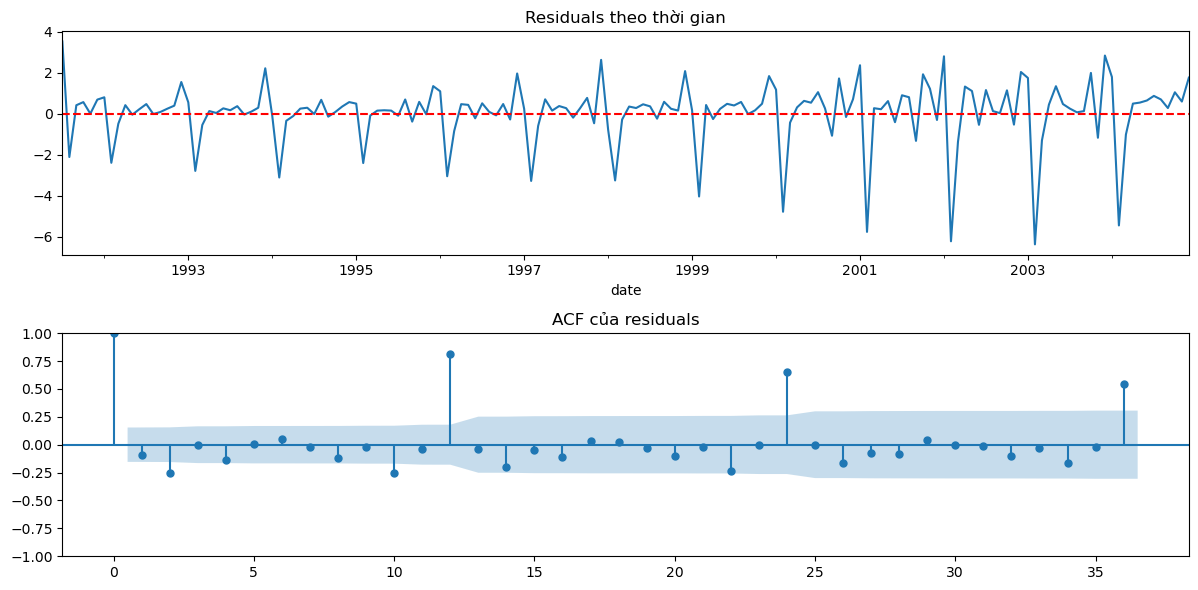

,lb_stat,lb_pvalue
12,146.166910,3.392315e-25
24,252.071731,6.410702e-40


In [60]:
resid = model_fit.resid.dropna()
print(f"Mean residual: {resid.mean():.4f}")

fig, axes = plt.subplots(2, 1, figsize=(12, 6))
resid.plot(ax=axes[0], title="Residuals theo thời gian")
axes[0].axhline(0, color="red", linestyle="--")
plot_acf(resid, lags=36, ax=axes[1], title="ACF của residuals")
plt.tight_layout(); plt.show()

acorr_ljungbox(resid, lags=[12, 24], return_df=True)

### Dự đoán trên tập test

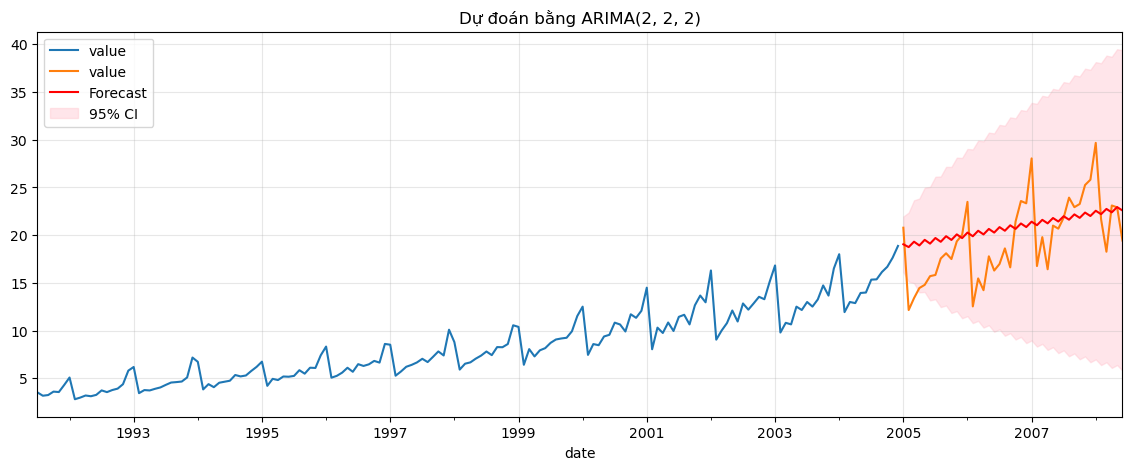

In [61]:
fc   = model_fit.get_forecast(steps=len(test_data))
pred = pd.Series(fc.predicted_mean.to_numpy(), index=test_data.index)
ci   = fc.conf_int()

fig, ax = plt.subplots(figsize=(14, 5))
train_data.plot(ax=ax, label="Train")
test_data.plot(ax=ax, label="Test")
pred.plot(ax=ax, label="Forecast", color="red")
ax.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1], color="pink", alpha=0.4, label="95% CI")
ax.set_title(f"Dự đoán bằng ARIMA({p}, {d}, {p})")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

In [62]:
err  = test_data["value"] - pred
mae  = err.abs().mean()
rmse = np.sqrt((err ** 2).mean())
mape = (err.abs() / test_data["value"]).mean() * 100

print(f"MAE  = {mae:.2f}")
print(f"RMSE = {rmse:.2f}")
print(f"MAPE = {mape:.2f}%")
print("Sai lệch lớn nhất:", err.abs().idxmax().date(), "=", round(err.abs().max(), 2))

MAE  = 3.04
RMSE = 3.65
MAPE = 17.46%
Sai lệch lớn nhất: 2006-02-01 = 7.35


### TEST VỚI SARIMA

In [69]:
P, D, Q, s = 1, 1, 1, 12
sarima = ARIMA(train_data, order=(p, d, q), seasonal_order=(P, D, Q, s))
sarima_fit = sarima.fit()

c:\Users\Wuan\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\Wuan\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\Wuan\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


Mean residual: 0.0188


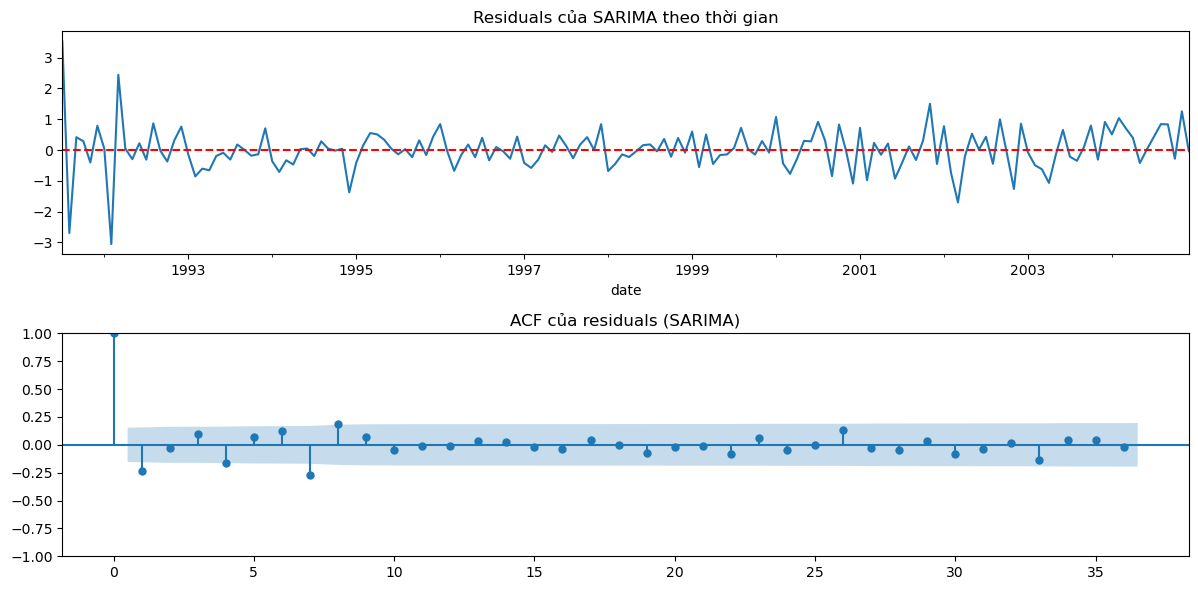

,lb_stat,lb_pvalue
12,38.535623,0.000125
24,42.805727,0.010467


In [70]:
resid_s = sarima_fit.resid.dropna()
print(f"Mean residual: {resid_s.mean():.4f}")

fig, axes = plt.subplots(2, 1, figsize=(12, 6))
resid_s.plot(ax=axes[0], title="Residuals của SARIMA theo thời gian")
axes[0].axhline(0, color="red", linestyle="--")
plot_acf(resid_s, lags=36, ax=axes[1], title="ACF của residuals (SARIMA)")
plt.tight_layout(); plt.show()

acorr_ljungbox(resid_s, lags=[12, 24], return_df=True)

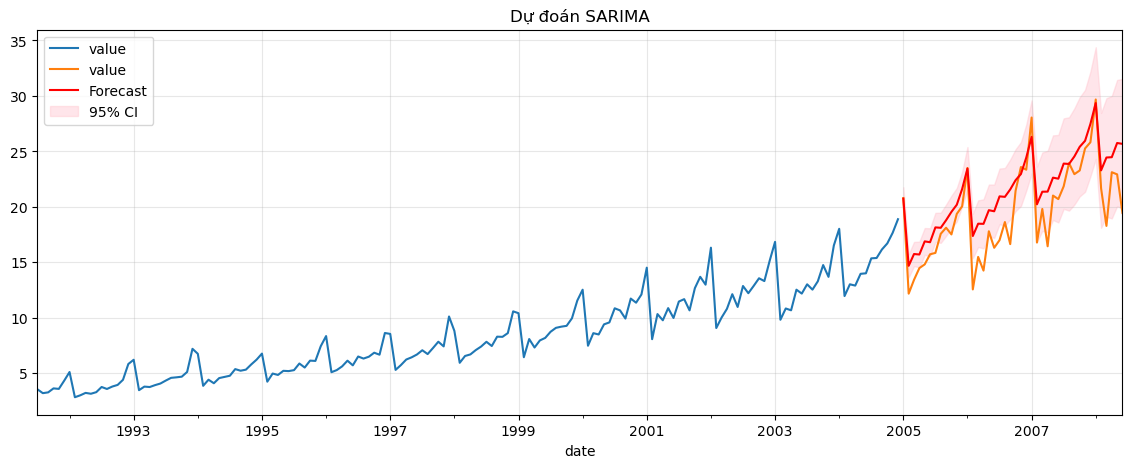

In [71]:
fc_s   = sarima_fit.get_forecast(steps=len(test_data))
pred_s = pd.Series(fc_s.predicted_mean.to_numpy(), index=test_data.index)
ci_s   = fc_s.conf_int()

fig, ax = plt.subplots(figsize=(14, 5))
train_data.plot(ax=ax, label="Train")
test_data.plot(ax=ax, label="Test")
pred_s.plot(ax=ax, label="Forecast", color="red")
ax.fill_between(ci_s.index, ci_s.iloc[:, 0], ci_s.iloc[:, 1], color="pink", alpha=0.4, label="95% CI")
ax.set_title(f"Dự đoán SARIMA")
ax.legend(); ax.grid(alpha=0.3)
plt.show()

In [72]:
err_s  = test_data["value"] - pred_s
mae_s  = err_s.abs().mean()
rmse_s = np.sqrt((err_s ** 2).mean())
mape_s = (err_s.abs() / test_data["value"]).mean() * 100

print(f"MAE  = {mae_s:.2f}")
print(f"RMSE = {rmse_s:.2f}")
print(f"MAPE = {mape_s:.2f}%")
print("Sai lệch lớn nhất:", err_s.abs().idxmax().date(), "=", round(err_s.abs().max(), 2))

MAE  = 2.15
RMSE = 2.65
MAPE = 12.31%
Sai lệch lớn nhất: 2008-06-01 = 6.23
